# Cell-label based region analysis (tumor core / margin / dist)

`skny.pp.calculate_region` is a variant of `skny.pp.calculate_distance` for **cell-level** data with annotated cell types
(e.g. a scanpy / Xenium 5K object). Instead of contouring the tumor from marker gene expression on a grid, the tumor is
defined by a **cell label** (here `"Malignant"`) and every cell is assigned to one of three regions:

| region | definition |
|---|---|
| `core` | grid bins within `nest_radius` (15 µm) of a tumor cell = the area actually occupied by tumor cells. No closing / hole filling, so stroma enclosed by tumor is **not** core. Isolated components with fewer than `min_nest_cells` (5) tumor cells are discarded. |
| `margin` | tissue outside the core and within `margin` (100 µm) of the core boundary (peri-tumoral stroma) |
| `dist` | tissue farther than `margin` from the core boundary |
| `outside` | outside the tissue mask (built from the density of *all* cells, so empty space is never counted as `dist`) |

`skny.pp.region_density` then counts cells of any group (e.g. immune subtypes) per region and divides by the region area (cells / mm²).

This tutorial uses synthetic data so that it runs without a download.

In [1]:
import numpy as np
import pandas as pd
import anndata as ad
import skny as sk
print(sk.__version__)

0.3.0


## 1. Synthetic data

Two samples. Each is a 1.5 × 1.5 mm tissue with one tumor nest (a disc of radius 300 µm); T cells and macrophages are scattered in the stroma, and some macrophages infiltrate the tumor.

In [2]:
rng = np.random.default_rng(0)
parts = []
for s, (cx, cy) in {"S1": (700, 700), "S2": (500, 900)}.items():
    n = 20000
    xy = rng.uniform(0, 1500, size=(n, 2))
    r = np.hypot(xy[:, 0] - cx, xy[:, 1] - cy)
    label = np.where(r < 300, "Malignant", "Fibroblast").astype(object)
    u = rng.random(n)
    label[(label == "Fibroblast") & (u < 0.10)] = "T cell"
    label[(label == "Fibroblast") & (u >= 0.10) & (u < 0.15)] = "Macrophage"
    label[(label == "Malignant") & (u < 0.03)] = "Macrophage"   # infiltrating macrophages
    obs = pd.DataFrame({"sample": s, "cell_type": label}, index=[f"{s}_{i}" for i in range(n)])
    a = ad.AnnData(obs=obs); a.obsm["spatial"] = xy      # coordinates in micrometres
    parts.append(a)
adata = ad.concat(parts)
adata.obs["cell_type"] = adata.obs["cell_type"].astype("category")
adata

AnnData object with n_obs × n_vars = 40000 × 0
    obs: 'sample', 'cell_type'
    obsm: 'spatial'

## 2. Regions

Coordinates must be in **micrometres** (`adata.obsm["spatial"]`, or two `obs` columns via `coord_keys=("x_um", "y_um")`). Regions are computed per sample when `sample_key` is given.

In [3]:
sk.pp.calculate_region(adata, "Malignant", label_key="cell_type", sample_key="sample")
adata.obs["region"].value_counts()

[skny] S1: core=0.304 mm2, margin=0.227 mm2, dist=2.428 mm2
[skny] S2: core=0.305 mm2, margin=0.228 mm2, dist=2.417 mm2


region
dist            30570
core             5387
margin           4043
outside             0
not_computed        0
Name: count, dtype: int64

The per-sample region maps, areas and the parameters are stored in `adata.uns["region"]`; the distance of every cell to the nearest tumor cell is in `adata.obs["region_dist_um"]`.

In [4]:
adata.uns["region"]["params"], {s: m["area_mm2"] for s, m in adata.uns["region"]["maps"].items()}

({'ref_label': ['Malignant'],
  'label_key': 'cell_type',
  'sample_key': 'sample',
  'bin_um': 10.0,
  'nest_radius': 15.0,
  'margin': 100.0,
  'min_nest_cells': 5,
  'min_ref_cells': 20,
  'tissue_smooth': 60.0,
  'tissue_min_density': 250.0,
  'min_tissue_area': 0.1,
  'core_only': False,
  'margin_from': 'nest'},
 {'S1': {'core': 0.3037, 'margin': 0.2269, 'dist': 2.4277},
  'S2': {'core': 0.305, 'margin': 0.228, 'dist': 2.4167}})

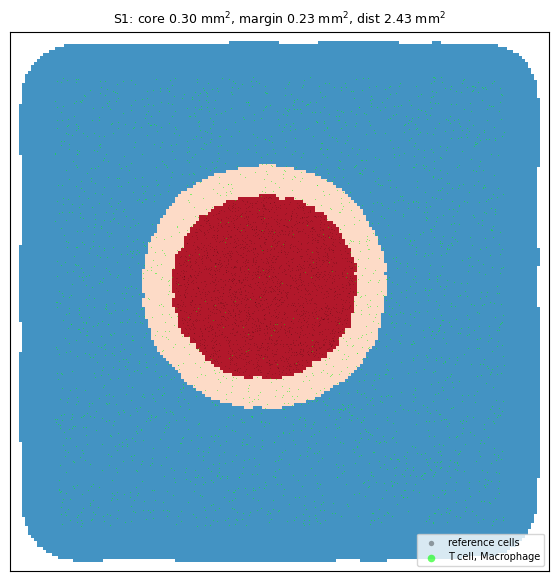

<Axes: title={'center': 'S1: core 0.30 mm$^2$, margin 0.23 mm$^2$, dist 2.43 mm$^2$'}>

In [5]:
sk.pl.region_map(adata, sample="S1", highlight=["T cell", "Macrophage"])

## 3. Density per region

In [6]:
df = sk.pp.region_density(adata, "cell_type", sample_key="sample", groups=["T cell", "Macrophage"])
df

,sample,region,group,n,area_mm2,density
0,S1,core,T cell,15,0.3037,49.390846
1,S1,core,Macrophage,78,0.3037,256.832400
2,S1,core,_all_cells,2697,0.3037,8880.474152
3,S1,margin,T cell,189,0.2269,832.966064
4,S1,margin,Macrophage,116,0.2269,511.238431
5,S1,margin,_all_cells,2031,0.2269,8951.079771
6,S1,dist,T cell,1554,2.4277,640.112040
7,S1,dist,Macrophage,740,2.4277,304.815257
8,S1,dist,_all_cells,15272,2.4277,6290.727849
9,S2,core,T cell,16,0.3050,52.459016


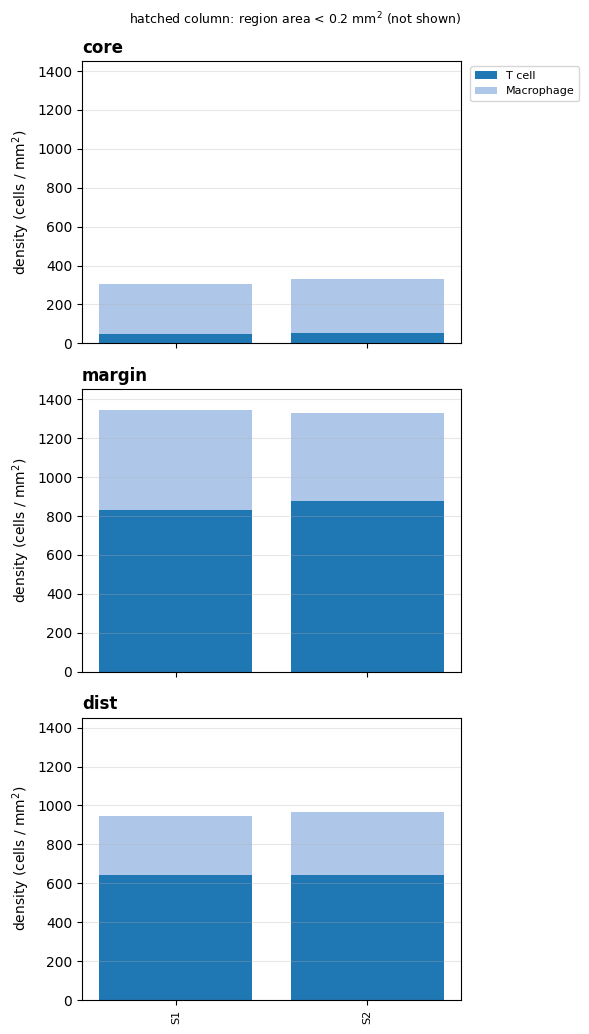

In [7]:
fig, axes = sk.pl.region_density_plot(df, groups=["T cell", "Macrophage"], min_area_mm2=0.2)

Regions whose area is below `min_area_mm2` are hidden with a hatch instead of showing an unstable density.

## Notes

* `margin_from="reference"` reproduces the legacy behaviour in which the margin is measured from *any* reference cell, so isolated tumor cells that were discarded from the core still create a margin halo. The default (`"nest"`) measures it from the retained core boundary.
* `core_only=True` defines only the core (useful for a second reference label, e.g. a rare tumor subpopulation, whose core is compared with the main tumor core of the same sample).
* Use `key_added` to keep several region definitions side by side (`region`, `region_morula`, ...). `sk.pp.region_density(..., region_key=...)` and `sk.pl.region_map(..., region_key=...)` read the matching one.